In [18]:
# Cell 1: Imports
import os
import mne
import numpy as np
import matplotlib.pyplot as plt
from mne.preprocessing import ICA, create_eog_epochs


In [19]:
# Cell 2: Config
# Paths
input_path =  "C:/Users/sanja/Desktop/EEG_Project/EEG/eeg/sub-001/eeg/sub-001_task-eyesclosed_eeg.set"
output_dir = "./eeg_out"
os.makedirs(output_dir, exist_ok=True)


In [20]:
# Cell 3: Load Data
raw = mne.io.read_raw_eeglab(input_path, preload=True)
raw.info


<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, Fp2, F3, F4, C3, C4, P3, P4, O1, O2, F7, F8, T3, T4, T5, ...
 chs: 19 EEG
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.0 Hz
 lowpass: 250.0 Hz
 meas_date: unspecified
 nchan: 19
 projs: []
 sfreq: 500.0 Hz
>

In [21]:
# Cell 4: Re-reference
if all(ch in raw.ch_names for ch in ["A1", "A2"]):
    raw.set_eeg_reference(["A1", "A2"])
else:
    raw.set_eeg_reference("average")


EEG channel type selected for re-referencing
Applying average reference.
Applying a custom ('EEG',) reference.


In [22]:
# Cell 5: Filtering (FIR)
raw.filter(0.5, 45., fir_design='firwin')


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 45 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 45.00 Hz
- Upper transition bandwidth: 11.25 Hz (-6 dB cutoff frequency: 50.62 Hz)
- Filter length: 3301 samples (6.602 s)



<RawEEGLAB | sub-001_task-eyesclosed_eeg.set, 19 x 299900 (599.8 s), ~43.5 MiB, data loaded>

In [23]:
# Cell 6: Bad window detection
raw_copy = raw.copy()
data = raw_copy.get_data()
window_size = int(raw.info["sfreq"] * 2)  # 2 sec windows
num_windows = data.shape[1] // window_size

bad_windows = []
for w in range(num_windows):
    segment = data[:, w*window_size:(w+1)*window_size]
    if np.std(segment) > 100e-6:  # threshold
        bad_windows.append([w*2, (w+1)*2])

# Only add annotations if bad windows are found
if bad_windows:
    annots = mne.Annotations(
        onset=[bw[0] for bw in bad_windows],
        duration=[2]*len(bad_windows),
        description=['bad_window']*len(bad_windows)
    )
    raw.set_annotations(annots)
else:
    print("No bad windows detected.")


In [31]:
# Cell 7: ICA (artifact removal)

# Automatically set ICA components to number of channels - 1
n_channels = len(raw.ch_names)
n_components = min(20, n_channels - 1)  # ensures ICA < total channels

ica = ICA(n_components=n_components, random_state=97)
ica.fit(raw)

# Detect and remove EOG artifacts if present
try:
    eog_epochs = create_eog_epochs(raw)
    eog_inds, scores = ica.find_bads_eog(eog_epochs)
    ica.exclude = eog_inds
    print(f"Excluded {len(eog_inds)} EOG components: {eog_inds}")
except Exception as e:
    print("EOG detection skipped:", e)

# Apply ICA
raw_clean = raw.copy()
ica.apply(raw_clean)


Fitting ICA to data using 19 channels (please be patient, this may take a while)
Omitting 1000 of 299900 (0.33%) samples, retaining 298900 (99.67%) samples.
Selecting by number: 18 components
Fitting ICA took 5.0s.
EOG detection skipped: No EOG channel(s) found
Applying ICA to Raw instance
    Transforming to ICA space (18 components)
    Zeroing out 0 ICA components
    Projecting back using 19 PCA components


<RawEEGLAB | sub-001_task-eyesclosed_eeg.set, 19 x 299900 (599.8 s), ~43.5 MiB, data loaded>

In [26]:
# Cell 8: Save Clean Data
clean_path = os.path.join(output_dir, "cleaned_raw.fif")
raw_clean.save(clean_path, overwrite=True)


Writing C:\Users\sanja\eeg_out\cleaned_raw.fif
Closing C:\Users\sanja\eeg_out\cleaned_raw.fif
[done]


[WindowsPath('C:/Users/sanja/eeg_out/cleaned_raw.fif')]

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().
Setting 1000 of 299900 (0.33%) samples to NaN, retaining 298900 (99.67%) samples.
Effective window size : 4.096 (s)
Plotting power spectral density (dB=True).


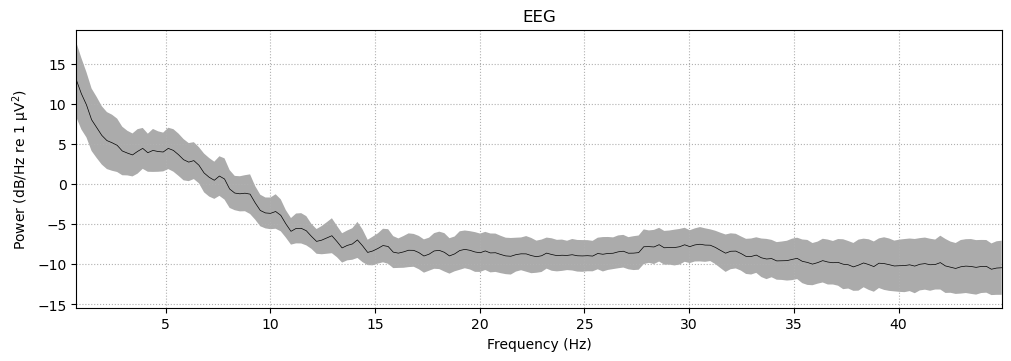

In [27]:
# Cell 9: PSD Plot
fig = raw_clean.plot_psd(fmin=0.5, fmax=45, average=True, show=False)
fig.savefig(os.path.join(output_dir, "psd_plot.png"))


In [32]:
# PSD comparison plot: paste this whole cell into your notebook
import numpy as np
import matplotlib.pyplot as plt
import mne
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ---------- Optional: load data if you don't have raw_before/raw_after ----------
# Uncomment and edit paths if needed.
# raw_before = mne.io.read_raw_eeglab("path/to/original.set", preload=True)
# raw_after  = mne.io.read_raw_fif("path/to/cleaned_raw.fif", preload=True)

# ---------- Parameters ----------
fmin_plot, fmax_plot = 0.5, 50.0     # plotting range (Hz)
psd_fmin, psd_fmax = 0.5, 50.0       # PSD computation frequency range
alpha_band = (8.0, 12.0)             # alpha band for topomap
n_fft = 2048                         # adjust depending on sfreq & signal length
average_line_width = 2.4
line_alpha = 0.7
figsize = (14, 6)
savepath = "psd_before_after.png"    # set to None to avoid saving

# quick checks
for name in ("raw_before", "raw_after"):
    if name not in globals():
        raise RuntimeError(f"Please provide an MNE Raw named '{name}' before running this cell.")

raws = [raw_before, raw_after]
titles = ["Original EEG PSD (0-50 Hz)", "Preprocessed EEG PSD (0-50 Hz)"]

# pick EEG channels only
picks = [mne.pick_types(r.info, eeg=True, meg=False) for r in raws]
if any(len(p)==0 for p in picks):
    raise RuntimeError("No EEG channels found in one of the Raw objects. Check channel types.")

# compute PSDs (units: V^2/Hz). We'll convert to µV^2/Hz and to dB.
psd_list = []
freqs = None
for r, p in zip(raws, picks):
    # use Welch PSD on continuous data
    psd, freqs = mne.time_frequency.psd_welch(
        r, picks=p, fmin=psd_fmin, fmax=psd_fmax,
        n_fft=n_fft, n_overlap=n_fft // 2, average='mean', verbose=False
    )
    # psd shape: (n_channels, n_freqs) in V^2/Hz
    psd_uv = psd * 1e12                  # V^2/Hz -> µV^2/Hz (1 V = 1e6 µV; squared -> 1e12)
    psd_db = 10.0 * np.log10(psd_uv)     # convert to dB
    psd_list.append(psd_db)

# pick frequency index range to plot
fmask = (freqs >= fmin_plot) & (freqs <= fmax_plot)
freqs_plot = freqs[fmask]

# Compute alpha power per channel for topomap (average power across alpha band)
alpha_powers = []
for r, p in zip(raws, picks):
    # compute PSD but restrict to alpha band for power estimation (could reuse above but this is explicit)
    psd_a, freqs_a = mne.time_frequency.psd_welch(
        r, picks=p, fmin=alpha_band[0], fmax=alpha_band[1],
        n_fft=n_fft, n_overlap=n_fft // 2, average='mean', verbose=False
    )
    psd_a_uv = psd_a * 1e12
    # average across frequency bins to get channel alpha power
    alpha_power_chan = psd_a_uv.mean(axis=1)
    alpha_powers.append(alpha_power_chan)

# ---------- Plotting ----------
fig, axes = plt.subplots(1, 2, figsize=figsize, sharey=True)
for ax, psd_db, title, r, p, alpha_power in zip(axes, psd_list, titles, raws, picks, alpha_powers):
    # plot per-channel thin lines
    for ch_idx in range(psd_db.shape[0]):
        ax.plot(freqs_plot, psd_db[ch_idx, fmask], linewidth=0.9, alpha=line_alpha, zorder=1)
    # plot channel-average thicker
    avg_db = psd_db.mean(axis=0)
    ax.plot(freqs_plot, avg_db[fmask], color='black', linewidth=average_line_width, zorder=3, label='average')
    ax.set_title(title)
    ax.set_xlabel('Frequency (Hz)')
    ax.grid(True, linestyle=':', linewidth=0.6)
    ax.set_xlim(fmin_plot, fmax_plot)
    ax.axvline(x=fmin_plot, color='gray', linestyle='--', linewidth=1.0)
    ax.axvline(x=fmax_plot, color='gray', linestyle='--', linewidth=1.0)
    ax.tick_params(axis='both', which='major')

    # add small topomap inset for alpha power
    # create an inset axis
    inset = inset_axes(ax, width="22%", height="22%", loc='upper right', borderpad=1.0)
    # Need an info object with channel positions; create picks order mapping
    ch_names = [r.ch_names[i] for i in p]
    # build info for topomap using the raw's info (mne handles name mapping)
    # plot_topomap expects data matching channels in info-> use picks
    mne.viz.plot_topomap(
        alpha_power, r.info, axes=inset, show=False,
        names=None, show_names=False, contours=4
    )
    inset.set_title("", fontsize=8)
    # add a tiny label
    inset.text(0.5, -0.2, 'alpha 8-12Hz', ha='center', va='top', fontsize=7, transform=inset.transAxes)

# y-label shared
axes[0].set_ylabel('µV²/Hz (dB)')

# legend on the right plot
axes[1].legend(loc='upper left')

plt.tight_layout()
if savepath:
    fig.savefig(savepath, dpi=200, bbox_inches='tight')
plt.show()


RuntimeError: Please provide an MNE Raw named 'raw_before' before running this cell.